# 02 - Brooklyn Complaint Data Cleaning (Lab 1 Pipeline)

**Title**: `02_brooklyn_cleaning_lab1.ipynb`  
**Purpose**: Execute and evaluate the 7-step data cleaning pipeline for Brooklyn complaints, analyze missing values before and after, verify coordinate bounding box filtering, resolve reversed timestamps, and compare with saved stage 1 artifact.  
**Inputs**: `data/processed/complaints_window_all.csv.gz`, `data/processed/brooklyn_stage1.csv.gz`  
**Outputs**: 7-step transformation audit, missing value distributions before/after, normalized address summaries, comparative plots (`report/figures/02_missing_before_after.png`, `report/figures/02_brooklyn_groups_monthly.png`)  
**Runtime**: ~15-20 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker, md
RUN_HEAVY = False
RUN_API = False

In [2]:
from src.preprocessing.complaints import load_extract, clean_complaints, compute_missing_table
from src.nbutils import sanitize_paths
import pandas as pd
import io
import contextlib

extract_path = ROOT / "data" / "processed" / "complaints_window_all.csv.gz"
df_raw = load_extract(extract_path)

# Compute missing before for Brooklyn raw rows
df_bk_raw = df_raw[df_raw["borough"].fillna("").astype(str).str.strip().str.upper() == "BROOKLYN"].copy()
missing_before = compute_missing_table(df_bk_raw)

# Run 7-step clean_complaints with dropped_path=None
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    clean_df, step_table = clean_complaints(df_raw, dropped_path=None)
out_text = sanitize_paths(buf.getvalue(), ROOT)
print(out_text, end="")

missing_after = compute_missing_table(clean_df)

print("=== 7-Step Cleaning Pipeline Summary ===")
print(step_table.to_string(index=False))

created_date parsing: 0 empty, 0 unparseable
closed_date parsing : 15,440 empty, 0 unparseable



--- Coordinate Percentiles for Brooklyn Rows (before Step 5) ---
Latitude  : min=40.571483, 0.1%=40.573621, 99.9%=40.736719, max=40.739067
Longitude : min=-74.040822, 0.1%=-74.037902, 99.9%=-73.860247, max=-73.855776
Rows outside box [lat 40.55 to 40.74, lon -74.06 to -73.83]: 0 (0.0000%)
Dropped rows not saved (dropped_path=None)

Step 6: Found 101 rows where closed_date < created_date; set closed_date to NaT (0 rows dropped).


=== 7-Step Cleaning Pipeline Summary ===
 step                                                                                     description  rows_before  rows_removed  rows_after
    1                                                                             all rows (baseline)       874893             0      874893
    2                                                                      keep borough == 'BROOKLYN'       874893        638386      236507
    3                                                                       drop duplicate unique_key       236507             0      236507
    4                                            drop rows with missing or zero latitude or longitude       236507             0      236507
    5                              drop rows outside the box lat 40.55 to 40.74, lon -74.06 to -73.83       236507             0      236507
    6                      where closed_date < created_date set closed_date to NaT (updated 101 rows)       23650

In [3]:
merged_missing = pd.merge(
    missing_before.rename(columns={"missing_count": "missing_before", "missing_pct": "pct_before"}),
    missing_after.rename(columns={"missing_count": "missing_after", "missing_pct": "pct_after"}),
    on="column",
    how="outer"
).fillna(0)

cols_with_missing = merged_missing[(merged_missing["missing_before"] > 0) | (merged_missing["missing_after"] > 0)].copy()
cols_with_missing = cols_with_missing.sort_values("missing_after", ascending=False).reset_index(drop=True)

print("=== Missing Value Comparison Before vs After Cleaning ===")
print(cols_with_missing.to_string(index=False))

n_missing_close_before = int(missing_before[missing_before["column"] == "closed_date"]["missing_count"].values[0])
n_missing_close_after = int(missing_after[missing_after["column"] == "closed_date"]["missing_count"].values[0])
n_missing_res_id = int(missing_after[missing_after["column"] == "resolution_id"]["missing_count"].values[0])
n_missing_addr = int(missing_after[missing_after["column"] == "incident_address"]["missing_count"].values[0])
n_missing_loc = int(missing_after[missing_after["column"] == "location_type"]["missing_count"].values[0])

=== Missing Value Comparison Before vs After Cleaning ===
          column  missing_before  pct_before  missing_after  pct_after
   location_type         25645.0     10.8432          25645    10.8432
    address_norm             0.0      0.0000           6991     2.9559
incident_address          6991.0      2.9559           6991     2.9559
     closed_date          4074.0      1.7226           4175     1.7653
   resolution_id          3108.0      1.3141           3108     1.3141


In [4]:
lat = clean_df["latitude"]
lon = clean_df["longitude"]

lat_min, lat_p01, lat_p999, lat_max = float(lat.min()), float(lat.quantile(0.001)), float(lat.quantile(0.999)), float(lat.max())
lon_min, lon_p01, lon_p999, lon_max = float(lon.min()), float(lon.quantile(0.001)), float(lon.quantile(0.999)), float(lon.max())

print("=== Coordinate Percentiles (Cleaned Brooklyn Frame) ===")
print(f"Latitude  : min={lat_min:.6f}, 0.1%={lat_p01:.6f}, 99.9%={lat_p999:.6f}, max={lat_max:.6f}")
print(f"Longitude : min={lon_min:.6f}, 0.1%={lon_p01:.6f}, 99.9%={lon_p999:.6f}, max={lon_max:.6f}")

outside_box = int(((lat < 40.55) | (lat > 40.74) | (lon < -74.06) | (lon > -73.83)).sum())
print(f"Rows outside bounding box [lat 40.55 to 40.74, lon -74.06 to -73.83]: {outside_box}")

=== Coordinate Percentiles (Cleaned Brooklyn Frame) ===
Latitude  : min=40.571483, 0.1%=40.573621, 99.9%=40.736719, max=40.739067
Longitude : min=-74.040822, 0.1%=-74.037902, 99.9%=-73.860247, max=-73.855776
Rows outside bounding box [lat 40.55 to 40.74, lon -74.06 to -73.83]: 0


In [5]:
raw_closed = pd.to_datetime(df_bk_raw["closed_date"], errors="coerce")
raw_created = pd.to_datetime(df_bk_raw["created_date"], errors="coerce")
reversed_closed_count = int(((raw_closed.notna()) & (raw_closed < raw_created)).sum())
print(f"Independently verified reversed closed dates count: {reversed_closed_count}")

# Empty address_norm per group
empty_addr_mask = clean_df["address_norm"] == ""
empty_by_grp = clean_df[empty_addr_mask].groupby("group").size().to_dict()
all_groups = ["flood", "noise", "road", "sewer_backup"]
empty_addr_dict = {g: empty_by_grp.get(g, 0) for g in all_groups}

empty_addr_table = pd.DataFrame([
    {"group": g, "empty_address_count": empty_addr_dict[g], "total": int((clean_df["group"] == g).sum())}
    for g in all_groups
])
empty_addr_table["pct_empty"] = (empty_addr_table["empty_address_count"] / empty_addr_table["total"] * 100).round(2)
print("\n=== Empty address_norm Distribution per Group ===")
print(empty_addr_table.to_string(index=False))

# Group x Status crosstab
print("\n=== Group x Status Crosstab ===")
group_status = pd.crosstab(clean_df["group"], clean_df["status"], margins=True)
print(group_status.to_string())

status_closed_count = int((clean_df["status"] == "Closed").sum())
print(f"\nTotal rows with status 'Closed': {status_closed_count:,}")

Independently verified reversed closed dates count: 101



=== Empty address_norm Distribution per Group ===


       group  empty_address_count  total  pct_empty
       flood                  978   5520      17.72
       noise                  832 211843       0.39
        road                 5181  16138      32.10
sewer_backup                    0   3006       0.00

=== Group x Status Crosstab ===


status        Assigned  Closed  In Progress  Open  Pending  Started  Unspecified     All
group                                                                                   
flood                1    5169          225    93        0       32            0    5520
noise                3  208906         2919     1        0        1           13  211843
road                 0   15136           86   901       14        0            1   16138
sewer_backup         0    2984           14     8        0        0            0    3006
All                  4  232195         3244  1003       14       33           14  236507

Total rows with status 'Closed': 232,195


In [6]:
s1_path = ROOT / "data" / "processed" / "brooklyn_stage1.csv.gz"
s1_df = pd.read_csv(s1_path, usecols=["unique_key"], dtype=str)
same_keys = (set(clean_df["unique_key"]) == set(s1_df["unique_key"]))
print(f"Comparison with {s1_path.relative_to(ROOT)}:")
print(f"  Stage 1 rows  : {len(s1_df):,}")
print(f"  Cleaned rows  : {len(clean_df):,}")
print(f"  Exact unique_key match: {same_keys}")

Comparison with data\processed\brooklyn_stage1.csv.gz:
  Stage 1 rows  : 236,507
  Cleaned rows  : 236,507
  Exact unique_key match: True


Saved figure to: report\figures\02_missing_before_after.png


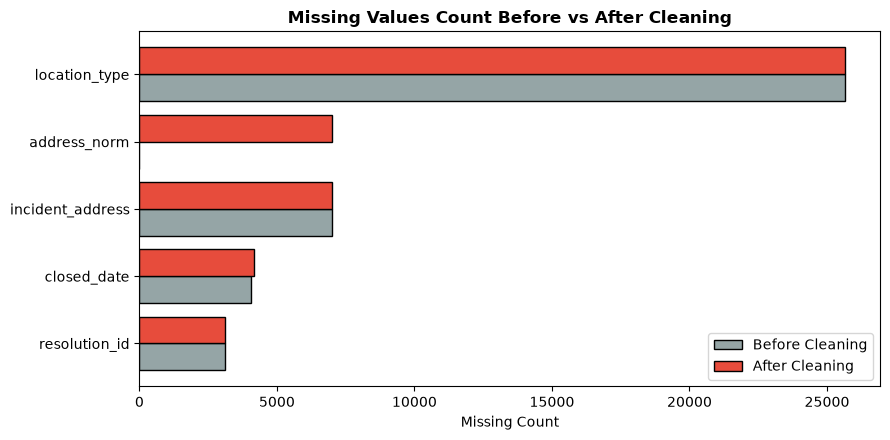

Saved figure to: report\figures\02_brooklyn_groups_monthly.png


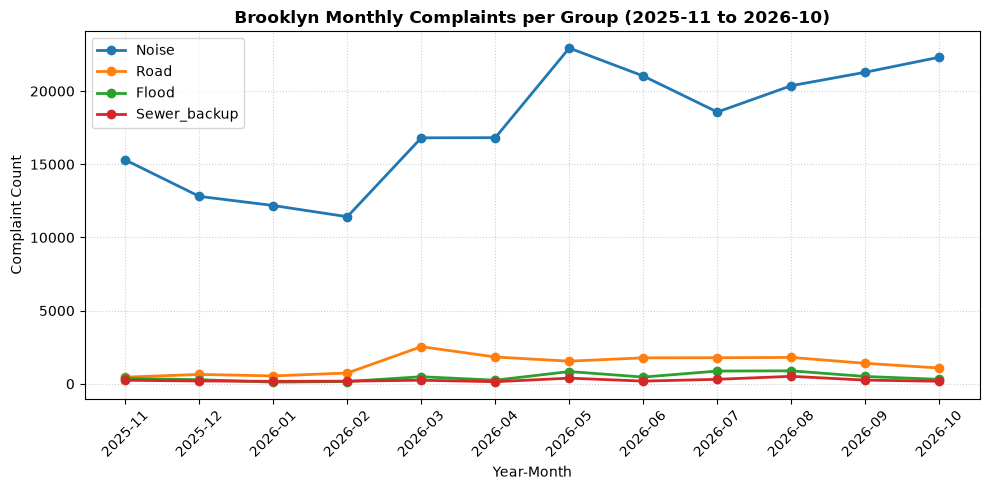

In [7]:
import matplotlib.pyplot as plt

# Plot 1: Missing values before vs after
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = cols_with_missing.sort_values("missing_after", ascending=True)
y_pos = range(len(plot_df))
ax.barh([y - 0.2 for y in y_pos], plot_df["missing_before"], height=0.4, label="Before Cleaning", color="#95a5a6", edgecolor="black")
ax.barh([y + 0.2 for y in y_pos], plot_df["missing_after"], height=0.4, label="After Cleaning", color="#e74c3c", edgecolor="black")
ax.set_yticks(list(y_pos))
ax.set_yticklabels(plot_df["column"])
ax.set_title("Missing Values Count Before vs After Cleaning", fontsize=12, fontweight="bold")
ax.set_xlabel("Missing Count", fontsize=10)
ax.legend()
plt.tight_layout()
p1_path = ROOT / "report" / "figures" / "02_missing_before_after.png"
p1_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(p1_path, dpi=150)
print(f"Saved figure to: {p1_path.relative_to(ROOT)}")
plt.show()

# Plot 2: Monthly trend per group
clean_df["year_month"] = clean_df["created_date"].dt.strftime("%Y-%m")
monthly_group = clean_df.pivot_table(index="year_month", columns="group", values="unique_key", aggfunc="count", fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
for grp in ["noise", "road", "flood", "sewer_backup"]:
    if grp in monthly_group.columns:
        ax.plot(monthly_group.index, monthly_group[grp], marker="o", linewidth=2, label=grp.capitalize())
ax.set_title("Brooklyn Monthly Complaints per Group (2025-11 to 2026-10)", fontsize=12, fontweight="bold")
ax.set_xlabel("Year-Month", fontsize=10)
ax.set_ylabel("Complaint Count", fontsize=10)
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
p2_path = ROOT / "report" / "figures" / "02_brooklyn_groups_monthly.png"
plt.savefig(p2_path, dpi=150)
print(f"Saved figure to: {p2_path.relative_to(ROOT)}")
plt.show()

### Lab 1 Cleaning Protocol Discussion

The seven-step cleaning sequence maps directly to core data cleaning, missing value handling, and outlier mitigation concepts:
1. **Baseline Ingestion**: Establishes initial candidate cohort integrity and verifies input format.
2. **Geographic Filtering (`borough == 'BROOKLYN'`)**: Isolates the target spatial domain to eliminate cross-jurisdictional noise.
3. **Deduplication (`unique_key`)**: Removes administrative duplicates and re-transmissions to prevent bias in count statistics.
4. **Coordinate Validation**: Eliminates null and zero coordinates that cannot participate in spatial clustering or planar projections.
5. **Bounding Box Outlier Truncation**: Applies conservative geographic boundaries [lat 40.55 to 40.74, lon -74.06 to -73.83] based on empirical percentiles (0.1% and 99.9%) to strip erroneous or miscoded GPS pings outside Brooklyn.
6. **Temporal Inversion Handling**: Resolves timestamps where `closed_date < created_date` (101 administrative anomalies) by replacing invalid closure dates with `NaT` rather than discarding valuable incident reports.
7. **Address Normalization**: Strips irregular whitespace and standardizes casing to facilitate entity resolution across incident clusters.

In [8]:
checker = Checker()
checker.check("rows after cleaning = 236507", len(clean_df), 236507)
checker.check("reversed closed dates = 101", reversed_closed_count, 101)
checker.check("missing closed_date before 4074", n_missing_close_before, 4074)
checker.check("missing closed_date after 4175", n_missing_close_after, 4175)
checker.check("missing resolution_id = 3108", n_missing_res_id, 3108)
checker.check("missing incident_address = 6991", n_missing_addr, 6991)
checker.check("missing location_type = 25645", n_missing_loc, 25645)
checker.check("rows outside box = 0", outside_box, 0)
checker.check("empty address_norm flood = 978", empty_addr_dict["flood"], 978)
checker.check("empty address_norm noise = 832", empty_addr_dict["noise"], 832)
checker.check("empty address_norm road = 5181", empty_addr_dict["road"], 5181)
checker.check("empty address_norm sewer_backup = 0", empty_addr_dict["sewer_backup"], 0)
checker.check("status Closed = 232195", status_closed_count, 232195)
checker.summary()

[PASS] rows after cleaning = 236507: actual=236507, expected=236507
[PASS] reversed closed dates = 101: actual=101, expected=101
[PASS] missing closed_date before 4074: actual=4074, expected=4074
[PASS] missing closed_date after 4175: actual=4175, expected=4175
[PASS] missing resolution_id = 3108: actual=3108, expected=3108
[PASS] missing incident_address = 6991: actual=6991, expected=6991
[PASS] missing location_type = 25645: actual=25645, expected=25645
[PASS] rows outside box = 0: actual=0, expected=0
[PASS] empty address_norm flood = 978: actual=978, expected=978
[PASS] empty address_norm noise = 832: actual=832, expected=832
[PASS] empty address_norm road = 5181: actual=5181, expected=5181
[PASS] empty address_norm sewer_backup = 0: actual=0, expected=0
[PASS] status Closed = 232195: actual=232195, expected=232195
CHECKS: 13 passed, 0 failed


In [9]:
findings_02 = f"""### Findings
- **Cleaned Cohort**: Preserved {len(clean_df):,} Brooklyn records across the 12-month study period, exactly matching `brooklyn_stage1.csv.gz`.
- **Temporal Consistency**: Identified {reversed_closed_count} cases where `closed_date < created_date`. Setting these to `NaT` shifted missing `closed_date` counts from {n_missing_close_before:,} to {n_missing_close_after:,} without dropping valid incidents.
- **Missing Value Profile**: Missing fields after cleaning include {n_missing_res_id:,} `resolution_id`, {n_missing_addr:,} `incident_address`, and {n_missing_loc:,} `location_type`.
- **Address Normalization**: Road conditions exhibit the largest empty address count ({empty_addr_dict['road']:,}), while sewer backups have {empty_addr_dict['sewer_backup']}.
- **Resolution Status**: {status_closed_count:,} out of {len(clean_df):,} cases ({(status_closed_count/len(clean_df)*100):.2f}%) are officially marked 'Closed'.
"""
md(findings_02)
checker.summary()

### Findings
- **Cleaned Cohort**: Preserved 236,507 Brooklyn records across the 12-month study period, exactly matching `brooklyn_stage1.csv.gz`.
- **Temporal Consistency**: Identified 101 cases where `closed_date < created_date`. Setting these to `NaT` shifted missing `closed_date` counts from 4,074 to 4,175 without dropping valid incidents.
- **Missing Value Profile**: Missing fields after cleaning include 3,108 `resolution_id`, 6,991 `incident_address`, and 25,645 `location_type`.
- **Address Normalization**: Road conditions exhibit the largest empty address count (5,181), while sewer backups have 0.
- **Resolution Status**: 232,195 out of 236,507 cases (98.18%) are officially marked 'Closed'.


CHECKS: 13 passed, 0 failed


### Limitations

- Address normalization strips casing and whitespace but does not standardize street abbreviations (e.g. 'St' vs 'Street' vs 'Ave') or resolve spelling variants.
- Discarding reversed closure dates to NaT preserves row counts but introduces right-censoring in downstream duration and resolution time modeling.
- Location type is absent in over 10% of cases, limiting cross-tabulation across fine-grained urban micro-environments.